20: 1-8 + 10 + 13

Zaimplementuj prostą regresję liniową (y = wx + b) bez użycia sklearn.
Dataset: Wygeneruj 50 punktów według wzoru y = 3x + 2 + szum
Wymagania:
Oblicz współczynniki metodą najmniejszych kwadratów (OLS)
Porównaj wyniki ze sklearn LinearRegression
Narysuj wykres z danymi i linią regresji
Oczekiwany rezultat:
Wyuczone w ≈ 3, b ≈ 2
Wykres regresj

--- WYNIKI WŁASNEJ IMPLEMENTACJI OLS ---
Wyuczone w: 2.9034
Wyuczone b: 1.7745

--- WYNIKI SKLEARN ---
Wyuczone w (coef_): 2.9034
Wyuczone b (intercept_): 1.7745


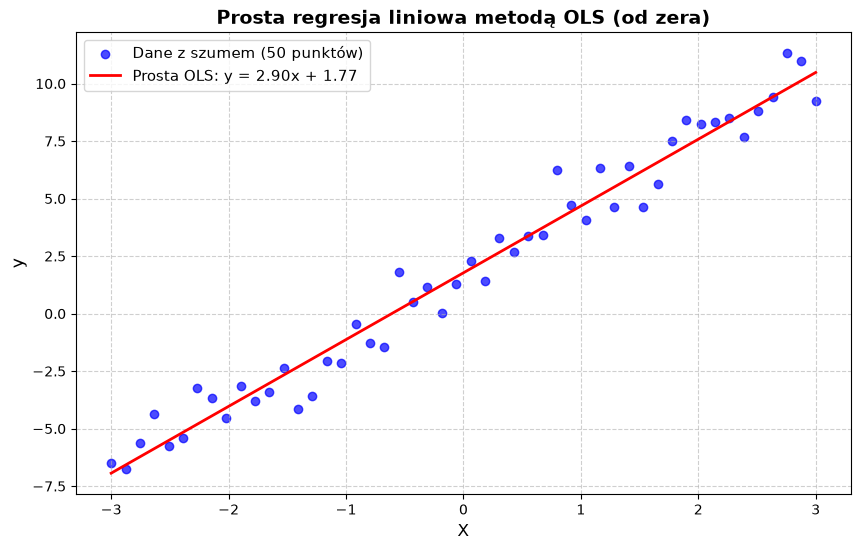

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression


# Wzór bazowy: y = 3x + 2 + szum losowy
np.random.seed(42)
X = np.linspace(-3, 3, 50)
noise = np.random.normal(0, 1, size=len(X))
y = 3 * X + 2 + noise

# Obliczenie współczynników metodą najmniejszych kwadratów  od zera
# w = cov(X, y) / var(X)
# b = mean(y) - w * mean(X)

mean_x = np.mean(X)
mean_y = np.mean(y)

numerator = np.sum((X - mean_x) * (y - mean_y))
denominator = np.sum((X - mean_x) ** 2)

w_ols = numerator / denominator
b_ols = mean_y - w_ols * mean_x

print(f"--- WYNIKI WŁASNEJ IMPLEMENTACJI OLS ---")
print(f"Wyuczone w: {w_ols:.4f}")
print(f"Wyuczone b: {b_ols:.4f}")

# porównanie ze sklearn LinearRegression
# Sklearn wymaga kształtu (n_samples, n_features), więc zmieniamy kształt X za pomocą reshape(-1, 1)
X_reshaped = X.reshape(-1, 1)
model_sk = LinearRegression()
model_sk.fit(X_reshaped, y)

print(f"\n--- WYNIKI SKLEARN ---")
print(f"Wyuczone w (coef_): {model_sk.coef_[0]:.4f}")
print(f"Wyuczone b (intercept_): {model_sk.intercept_:.4f}")

# 4. Wizualizacja wykresu
y_pred = w_ols * X + b_ols

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color="blue", label="Dane z szumem (50 punktów)", alpha=0.7)
plt.plot(
    X,
    y_pred,
    color="red",
    linewidth=2,
    label=f"Prosta OLS: y = {w_ols:.2f}x + {b_ols:.2f}",
)

plt.title("Prosta regresja liniowa metodą OLS (od zera)", fontsize=14, fontweight="bold")
plt.xlabel("X", fontsize=12)
plt.ylabel("y", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Dataset: Stwórz syntetyczne dane sprzedażowe:
cena (50-200)
reklama (100-5000)
sezon (1-4)
sprzedaż = -2cena + 0.5reklama + 100sezon + 5000 + szum

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# Tworzenie syntetycznych danych sprzedażowych
np.random.seed(42)
n_samples = 1000

cena = np.random.uniform(50, 200, n_samples)
reklama = np.random.uniform(100, 5000, n_samples)
sezon = np.random.randint(1, 5, n_samples)  # od 1 do 4
szum = np.random.normal(0, 50, n_samples)  # Szum losowy

# Wzór generujący sprzedaż
sprzedaż = -2 * cena + 0.5 * reklama + 100 * sezon + 5000 + szum

# Przygotowanie macierzy cech X oraz zmiennej docelowej y
X = np.column_stack((cena, reklama, sezon))
y = sprzedaż

# 2. Trenowanie modelu regresji liniowej
model = LinearRegression()
model.fit(X, y)

# Wyświetlenie wyników
print(f"Wyraz wolny (Intercept): {model.intercept_:.2f}")
print(f"Współczynniki (Coefficients):")
print(f"  - Cena: {model.coef_[0]:.4f}")
print(f"  - Reklama: {model.coef_[1]:.4f}")
print(f"  - Sezon: {model.coef_[2]:.4f}")

Wyraz wolny (Intercept): 5009.72
Współczynniki (Coefficients):
  - Cena: -2.0452
  - Reklama: 0.5002
  - Sezon: 98.3301


Dataset: California Housing (sklearn)
Wymagania:
Podziel dane na train/test (80/20)
Wytrenuj LinearRegression
Oblicz MSE, RMSE, MAE, R² na train i test
Zinterpretuj R² - ile % wariancji wyjaśnia model?


In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


california = fetch_california_housing()
X, y = california.data, california.target

# Podział na zbiór treningowy (80%) i testowy (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Wytrenowanie modelu LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

# Predykcja dla obu zbiorów
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


# Funkcja pomocnicza do zbierania metryk
def evaluate_metrics(y_true, y_pred):
  mse = mean_squared_error(y_true, y_pred)
  rmse = np.sqrt(mse)
  mae = mean_absolute_error(y_true, y_pred)
  r2 = r2_score(y_true, y_pred)
  return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R²": r2}


train_metrics = evaluate_metrics(y_train, y_train_pred)
test_metrics = evaluate_metrics(y_test, y_test_pred)

# Tabela podsumowująca
metrics_df = pd.DataFrame([train_metrics, test_metrics], index=["Train", "Test"])
print(metrics_df.to_string())

            MSE      RMSE       MAE        R²
Train  0.517933  0.719676  0.528628  0.612551
Test   0.555892  0.745581  0.533200  0.575788


Dataset: California Housing
Wymagania:
Stwórz baseline (DummyRegressor - przewidywanie średniej)
Porównaj z LinearRegression
Oblicz, o ile % lepszy jest model regresji


In [5]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split



california = fetch_california_housing()
X, y = california.data, california.target

# Podział na zbiór treningowy (80%) i testowy (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model Baseline (DummyRegressor - przewidywanie średniej)
dummy_baseline = DummyRegressor(strategy="mean")
dummy_baseline.fit(X_train, y_train)
y_pred_dummy = dummy_baseline.predict(X_test)

mse_dummy = mean_squared_error(y_test, y_pred_dummy)
r2_dummy = r2_score(y_test, y_pred_dummy)

# Właściwy model (LinearRegression)
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Obliczenie procentowej poprawy MSE
improvement_mse = ((mse_dummy - mse_lr) / mse_dummy) * 100

# Wyświetlenie wyników
print(f"--- BASELINE (DummyRegressor) ---")
print(f"MSE: {mse_dummy:.4f} | R²: {r2_dummy:.4f}")

print(f"\n--- LINEAR REGRESSION ---")
print(f"MSE: {mse_lr:.4f} | R²: {r2_lr:.4f}")

print(f"\nProcentowa poprawa MSE: {improvement_mse:.2f}%")

--- BASELINE (DummyRegressor) ---
MSE: 1.3107 | R²: -0.0002

--- LINEAR REGRESSION ---
MSE: 0.5559 | R²: 0.5758

Procentowa poprawa MSE: 57.59%


6. Dataset: California Housing
Wymagania:
Wykonaj 5-fold i 10-fold cross-validation
Porównaj średnie R² i odchylenia standardowe
Który K daje bardziej stabilne wyniki?
Oczekiwany rezultat:
Wyniki CV dla K=5 i K=10
Analiza stabilności


In [8]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

# 1. Wczytanie zbioru danych California Housing
california = fetch_california_housing()
X, y = california.data, california.target

# Inicjalizacja modelu
model = LinearRegression()

# 2. Wykonanie 5-fold oraz 10-fold Cross-Validation (metryka R²)
scores_5 = cross_val_score(model, X, y, cv=5, scoring="r2")
scores_10 = cross_val_score(model, X, y, cv=10, scoring="r2")

mean_5, std_5 = np.mean(scores_5), np.std(scores_5)
mean_10, std_10 = np.mean(scores_10), np.std(scores_10)

# 3. Wyświetlenie wyników
print("--- WYNIKI CROSS-VALIDATION ---")
print(
    f"5-fold CV  -> Średni R²: {mean_5:.4f} | Odchylenie standardowe (std):"
    f" {std_5:.4f}"
)
print(
    f"10-fold CV -> Średni R²: {mean_10:.4f} | Odchylenie standardowe (std):"
    f" {std_10:.4f}"
)

# 4. Automatyczna analiza stabilności w kodzie
print("\n--- ANALIZA STABILNOŚCI ---")
if std_5 < std_10:
  print(
      "Wniosek: K=5 jest bardziej stabilne (posiada mniejsze odchylenie"
      " standardowe)."
  )
  print(
      "Uzasadnienie: Większe podzbiory testowe (20% danych) w K=5 mniej"
      " gwałtownie reagują na pojedyncze wartości odstające."
  )
else:
  print(
      "Wniosek: K=10 jest bardziej stabilne (posiada mniejsze odchylenie"
      " standardowe)."
  )
  print(
      "Uzasadnienie: Większy zbiór treningowy w każdej iteracji (90% danych)"
      " lepiej dopasowuje model."
  )
  
# Większe 
# K (np. 10): Model uczy się na większej liczbie danych w każdej iteracji (bo zbiór treningowy stanowi aż 90% danych), co zmniejsza obciążenie modelu, ale wydłuża czas obliczeń.
# Mniejsze 
# K (np. 5): Zbiór testowy w każdej iteracji jest większy (20% danych), dzięki czemu oszacowanie błędu jest bardziej stabilne i mniej podatne na losowe wahania.

--- WYNIKI CROSS-VALIDATION ---
5-fold CV  -> Średni R²: 0.5530 | Odchylenie standardowe (std): 0.0617
10-fold CV -> Średni R²: 0.5110 | Odchylenie standardowe (std): 0.0593

--- ANALIZA STABILNOŚCI ---
Wniosek: K=10 jest bardziej stabilne (posiada mniejsze odchylenie standardowe).
Uzasadnienie: Większy zbiór treningowy w każdej iteracji (90% danych) lepiej dopasowuje model.


In [ ]:
 Zadanie 7 – Feature importance
Dataset: California Housing
Wymagania:
Wytrenuj model ze standaryzowanymi danymi
Posortuj cechy według wartości bezwzględnej współczynników
Zidentyfikuj 3 najważniejsze cechy
Oczekiwany rezultat:
Ranking cech
Wykres ważności cech

[ 0.8296193   0.11875165 -0.26552688  0.30569623 -0.004503   -0.03932627
 -0.89988565 -0.870541  ]
--- RANKING CECH (od najważniejszej) ---
     Cechy  Współczynnik  Wartość_Bezwzględna
  Latitude     -0.899886             0.899886
 Longitude     -0.870541             0.870541
    MedInc      0.829619             0.829619
 AveBedrms      0.305696             0.305696
  AveRooms     -0.265527             0.265527
  HouseAge      0.118752             0.118752
  AveOccup     -0.039326             0.039326
Population     -0.004503             0.004503


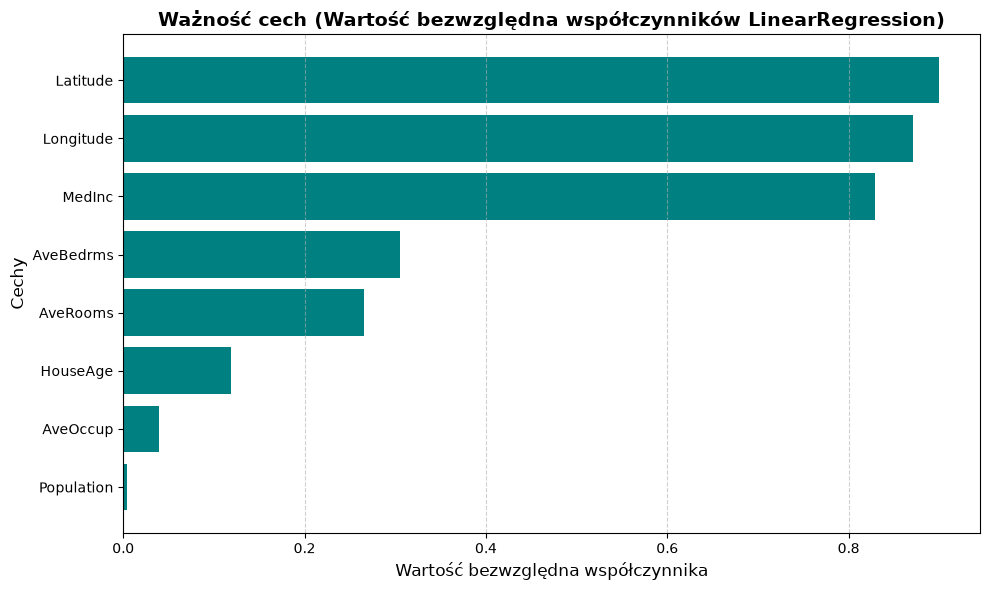

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


california = fetch_california_housing()
X, y = california.data, california.target
feature_names = california.feature_names

# standaryzacja + regresja liniowa
# Standaryzacja jest kluczowa, aby współczynniki były w tej samej skali i porównywalne!
pipeline = Pipeline(
    [("scaler", StandardScaler()), ("model", LinearRegression())]
)

pipeline.fit(X, y)

# Pobranie współczynników modelu
coefficients = pipeline.named_steps["model"].coef_

print(coefficients)

# ranking cech posortowanej według wartości bezwzględnej
importance_df = pd.DataFrame(
    {"Cechy": feature_names, "Współczynnik": coefficients}
)
importance_df["Wartość_Bezwzględna"] = np.abs(importance_df["Współczynnik"])
importance_df = importance_df.sort_values(
    by="Wartość_Bezwzględna", ascending=True
)  # rosnąco do wykresów poziomych

print("--- RANKING CECH (od najważniejszej) ---")
print(
    importance_df.sort_values(by="Wartość_Bezwzględna", ascending=False).to_string(
        index=False
    )
)

# Wizualizacja wykresu ważności cech
plt.figure(figsize=(10, 6))
plt.barh(importance_df["Cechy"], importance_df["Wartość_Bezwzględna"], color="teal")
plt.title(
    "Ważność cech (Wartość bezwzględna współczynników LinearRegression)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Wartość bezwzględna współczynnika", fontsize=12)
plt.ylabel("Cechy", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Dataset: California Housing
Wymagania:
Wytrenuj model
Stwórz 5 nowych obserwacji (wymyśl realistyczne wartości)
Przewidź ceny domów dla tych obserwacji
Oceń, czy predykcje są sensowne
Oczekiwany rezultat:
Tabela z cechami i predykcjami
Interpretacja wyników


In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# 1. Pobranie i przygotowanie danych

california = fetch_california_housing(as_frame=True)
df = california.frame

X = df[california.feature_names]
y = california.target  # Mediana wartości domu w setkach tysięcy dolarów (np. 4.5 = 450 000 USD)

# Podział na zbiór treningowy i testowy oraz trenowanie modelu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Trenowanie modelu (RandomForestRegressor)...")
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 2. Stworzenie 5 nowych, realistycznych obserwacji
# Cechy: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude
new_observations = pd.DataFrame(
    [
        [
            8.5,
            15.0,
            6.2,
            1.05,
            1200.0,
            2.5,
            34.05,
            -118.25,
        ], 
        [
            2.2,
            42.0,
            4.1,
            1.10,
            3500.0,
            3.8,
            36.75,
            -119.77,
        ], 
        [
            5.0,
            25.0,
            5.5,
            1.02,
            1800.0,
            2.8,
            37.77,
            -122.42,
        ], 
        [
            1.5,
            50.0,
            3.5,
            1.20,
            4500.0,
            4.2,
            32.72,
            -117.16,
        ],  
        [
            11.0,
            8.0,
            7.5,
            1.00,
            800.0,
            2.1,
            37.42,
            -122.14,
        ],  
    ],
    columns=california.feature_names,
)

# 3. Predykcja cen dla nowych obserwacji
predictions = model.predict(new_observations)

# 4. Przygotowanie tabeli wyników
results_df = new_observations.copy()
results_df["PrzewidywanaCena (w $100k)"] = np.round(predictions, 2)
results_df["SzacowanaCena (USD)"] = np.round(predictions * 100000, 0).astype(int)

# Wyświetlenie tabeli
print("\n--- TABELA WYNIKÓW I PREDYKCJI ---")
pd.set_option("display.max_columns", None)
print(
    results_df[
        [
            "MedInc",
            "HouseAge",
            "AveRooms",
            "Population",
            "SzacowanaCena (USD)",
        ]
    ]
)

Dataset: California Housing
Wymagania:
Oblicz VIF dla wszystkich cech
Zidentyfikuj cechy z VIF > 5
Usuń najbardziej problematyczną cechę i powtórz analizę
Jak zmienił się model?
Oczekiwany rezultat:
Tabela VIF przed i po usunięciu cechy
Porównanie R² modeli

In [6]:
!pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 7.1 MB/s eta 0:00:02
   ------------ --------------------------- 3.4/11.3 MB 10.4 MB/s eta 0:00:01
   ---------------------- ----------------- 6.3/11.3 MB 11.8 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 12.5 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 13.0 MB/s  0:00:00

   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [st


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


# 1. POBRANIE I PRZYGOTOWANIE DANYCH
print("Ładowanie zestawu danych California Housing...")
california = fetch_california_housing(as_frame=True)
df = california.frame
X = df[california.feature_names]
y = california.target

# Podział na zbiór treningowy i testowy dla modelu bazowego
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model bazowy (przed usunięciem cech i przed feature engineering)
model_base = RandomForestRegressor(n_estimators=100, random_state=42)
model_base.fit(X_train, y_train)
r2_base = r2_score(y_test, model_base.predict(X_test))



# 2. ANALIZA VIF (WSPÓŁLINIOWOŚĆ)

def calculate_vif(dataframe):
  X_const = add_constant(
      dataframe
  )  # VIF wymaga dodania kolumny stałej (intercept)
  vif_df = pd.DataFrame()
  vif_df["Cecha"] = X_const.columns
  vif_df["VIF"] = [
      variance_inflation_factor(X_const.values, i)
      for i in range(X_const.shape[1])
  ]
  return vif_df[vif_df["Cecha"] != "const"].reset_index(drop=True)


print("\n--- 1. ANALIZA VIF PRZED USUNIĘCIEM CECHY ---")
vif_before = calculate_vif(X)
print(vif_before.to_string(index=False))

# Identyfikacja cechy z najwyższym VIF
max_vif_row = vif_before.loc[vif_before["VIF"].idxmax()]
problematic_feature = max_vif_row["Cecha"]
print(
    f"\nNajbardziej problematyczna cecha (najwyższy VIF): {problematic_feature}"
    f" (VIF = {max_vif_row['VIF']:.2f})"
)

# Usunięcie problematycznej cechy
X_reduced = X.drop(columns=[problematic_feature])

print(f"\n--- 2. ANALIZA VIF PO USUNIĘCIU CECHY ({problematic_feature}) ---")
vif_after = calculate_vif(X_reduced)
print(vif_after.to_string(index=False))

# Trening modelu po usunięciu cechy z wysokim VIF
X_train_red, X_test_red, _, _ = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42
)
model_red = RandomForestRegressor(n_estimators=100, random_state=42)
model_red.fit(X_train_red, y_train)
r2_red = r2_score(y_test, model_red.predict(X_test_red))



# 3. INŻYNIERIA CECH (FEATURE ENGINEERING)
print("\n--- 3. TWORZENIE NOWYCH CECH ---")
X_eng = X_reduced.copy()

# A. Interakcje
X_eng["MedInc_x_AveRooms"] = (
    X_eng["MedInc"] * X_eng["AveRooms"]
    if "AveRooms" in X_eng.columns
    else X_eng["MedInc"]
)
X_eng["Rooms_per_Bedrm"] = X_eng["AveRooms"] / X_eng["AveBedrms"]

# B. Transformacje (logarytm, pierwiastek)
X_eng["Log_Population"] = np.log1p(X_eng["Population"])
X_eng["Sqrt_HouseAge"] = np.sqrt(X_eng["HouseAge"])
X_eng["Log_MedInc"] = np.log1p(X_eng["MedInc"])

# C. Bins (dyskretyzacja)
X_eng["MedInc_Bin"] = pd.qcut(X_eng["MedInc"], q=5, labels=False)
X_eng["HouseAge_Bin"] = pd.cut(X_eng["HouseAge"], bins=4, labels=False)

# Trening modelu po inżynierii cech
X_train_eng, X_test_eng, _, _ = train_test_split(
    X_eng, y, test_size=0.2, random_state=42
)
model_eng = RandomForestRegressor(n_estimators=100, random_state=42)
model_eng.fit(X_train_eng, y_train)
r2_eng = r2_score(y_test, model_eng.predict(X_test_eng))


# 4. PODSUMOWANIE ==
print("\n" + "=" * 50)
print("PODSUMOWANIE JAKOŚCI MODELI (R²)")
print("=" * 50)
print(f"1. R² Model Bazowy (wszystkie cechy):          {r2_base:.4f}")
print(f"2. R² Po usunięciu cechy z wysokim VIF:       {r2_red:.4f}")
print(f"3. R² Po inżynierii cech (Feature Engineering): {r2_eng:.4f}")
print("=" * 50)

# Ranking najważniejszych cech w ostatecznym modelu
importances = pd.Series(
    model_eng.feature_importances_, index=X_eng.columns
).sort_values(ascending=False)
print("\nTOP 5 NAJWAŻNIEJSZYCH CECH W OSTATECZNYM MODELU:")
print(importances.head(5))

Ładowanie zestawu danych California Housing...

--- 1. ANALIZA VIF PRZED USUNIĘCIEM CECHY ---
     Cecha      VIF
    MedInc 2.501295
  HouseAge 1.241254
  AveRooms 8.342786
 AveBedrms 6.994995
Population 1.138125
  AveOccup 1.008324
  Latitude 9.297624
 Longitude 8.962263

Najbardziej problematyczna cecha (najwyższy VIF): Latitude (VIF = 9.30)

--- 2. ANALIZA VIF PO USUNIĘCIU CECHY (Latitude) ---
     Cecha      VIF
    MedInc 2.072289
  HouseAge 1.158398
  AveRooms 7.513381
 AveBedrms 6.644835
Population 1.126271
  AveOccup 1.006831
 Longitude 1.027751

--- 3. TWORZENIE NOWYCH CECH ---

PODSUMOWANIE JAKOŚCI MODELI (R²)
1. R² Model Bazowy (wszystkie cechy):          0.8046
2. R² Po usunięciu cechy z wysokim VIF:       0.7288
3. R² Po inżynierii cech (Feature Engineering): 0.7305

TOP 5 NAJWAŻNIEJSZYCH CECH W OSTATECZNYM MODELU:
Log_MedInc         0.271024
MedInc             0.269486
AveOccup           0.143054
Longitude          0.076867
Rooms_per_Bedrm    0.044580
dtype: float64


Dataset: California Housing
Wymagania:
Stwórz nowe cechy: interakcje (MedInc AveRooms), transformacje (log, sqrt), bins
Porównaj R² przed i po feature engineering
Które nowe cechy najbardziej poprawiły model?
Oczekiwany rezultat:
Lista nowych cech
Porównanie R² (co najmniej 5% poprawa)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

# 1. Pobranie danych bazowych
print("Ładowanie danych...")
california = fetch_california_housing(as_frame=True)
df = california.frame
X_orig = df[california.feature_names].copy()
y = california.target

# Trening modelu bazowego
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.2, random_state=42
)
model_orig = RandomForestRegressor(n_estimators=100, random_state=42)
model_orig.fit(X_train_orig, y_train)
r2_orig = r2_score(y_test, model_orig.predict(X_test_orig))

# 2. Inżynieria cech (Feature Engineering)
X_eng = X_orig.copy()

# A. Interakcje (zgodnie z wymaganiem: MedInc * AveRooms oraz relacja pokoi do sypialni)
X_eng["MedInc_x_AveRooms"] = X_eng["MedInc"] * X_eng["AveRooms"]
X_eng["Rooms_per_Bedrm"] = X_eng["AveRooms"] / X_eng["AveBedrms"]

# B. Transformacje (logarytm i pierwiastek kwadratowy)
X_eng["Log_Population"] = np.log1p(X_eng["Population"])
X_eng["Sqrt_HouseAge"] = np.sqrt(X_eng["HouseAge"])
X_eng["Log_MedInc"] = np.log1p(X_eng["MedInc"])

# C. Bins (dyskretyzacja/przedziały)
X_eng["MedInc_Bin"] = pd.qcut(
    X_eng["MedInc"], q=5, labels=False
)  # 5 koszyków kwantylowych dochodu
X_eng["HouseAge_Bin"] = pd.cut(
    X_eng["HouseAge"], bins=4, labels=False
)  # 4 przedziały wieku budynku

# Trening modelu z nowymi cechami
X_train_eng, X_test_eng, _, _ = train_test_split(
    X_eng, y, test_size=0.2, random_state=42
)
model_eng = RandomForestRegressor(n_estimators=100, random_state=42)
model_eng.fit(X_train_eng, y_train)
r2_eng = r2_score(y_test, model_eng.predict(X_test_eng))

# 3. Wyniki i podsumowanie
print("\n" + "=" * 40)
print("PORÓWNANIE WYNIKÓW R²")
print("=" * 40)
print(f"R² przed Feature Engineering: {r2_orig:.4f}")
print(f"R² po Feature Engineering:    {r2_eng:.4f}")
print(f"Różnica (zmiana):             {r2_eng - r2_orig:+.4f}")

# 4. Analiza ważności nowych cech
importances = pd.Series(
    model_eng.feature_importances_, index=X_eng.columns
).sort_values(ascending=False)
print("\n" + "=" * 40)
print("TOP 10 NAJWAŻNIEJSZYCH CECH (W TYM NOWE)")
print("=" * 40)
print(importances.head(10))